# Working with raw DDM data

A hands-on guide to the ADC samples that `ddm capture` records: from one frame of raw data to
range, velocity and angle, in a few lines of numpy per step. Change the numbers and re-run the
cells to see what happens.

DDM in one paragraph: all three TX antennas transmit on every chirp, and TX *m* adds a phase
step to each chirp. That shifts its copy of every target by *m* Doppler sub-bands, so the
Doppler spectrum holds one copy per TX, a sub-band apart, and one empty sub-band that tells
which copy is TX0. Background: [Terms](architecture.md#terms) and
[Signal model](architecture.md#signal-model).

Run it with `uv run jupyter lab docs/raw_data.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from ddm.cfg import SPEED_OF_LIGHT, centre_frequency_hz, chirp_axes, chirp_period_us, ddm_params, parse_cfg
from ddm.cfg import profile as chirp_profile
from ddm.profile import load

plt.rcParams.update({"figure.dpi": 50, "figure.figsize": (7, 3), "image.cmap": "viridis"})
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "profiles").is_dir())

## 0. Get data

Set `CAPTURE` to a file from `uv run ddm capture profiles/template.toml -o wave.npz`. Each file
holds `frames[frame, chirp, rx, sample]` (complex ADC samples) and the configuration text that
was sent, so the axes below always match the data.

Without a capture, the next cell simulates one frame with the shipped profile.

In [2]:
CAPTURE = None  # e.g. ROOT / "wave.npz"

if CAPTURE is not None:
    data = np.load(CAPTURE)
    frames, cfg_text = data["frames"], str(data["config"])
else:
    cfg_text, _ = load(ROOT / "profiles" / "template.toml", "capture")
cfg = parse_cfg(cfg_text)
bands, num_tx = ddm_params(cfg)
p = chirp_profile(cfg)
chirp_period_s = chirp_period_us(cfg) * 1e-6
wavelength_m = SPEED_OF_LIGHT / centre_frequency_hz(cfg)
print(f"{bands} sub-bands, {num_tx} TX, chirp period {chirp_period_s * 1e6:.0f} us, "
      f"wavelength {wavelength_m * 1e3:.2f} mm")

4 sub-bands, 3 TX, chirp period 46 us, wavelength 3.79 mm


**Simulator.** One target at about 1 m, moving away at 1 m/s, 20° to the side, plus a static
reflector at 2 m. For each chirp *n*, TX *m* adds the phase code θ = m · n · 360° / N
(N = number of sub-bands; see [Signal model](architecture.md#signal-model)). The antenna positions are TI's
AWR1843AOP geometry (`sdk/packages/ti/board/antenna_geometry.c`, in units of λ/2): RX0..RX3 at
azimuth 3, 2, 1, 0 and TX0..TX2 at elevation 0, 1, 2. A target at elevation 0 therefore gives
every TX the same angle phase; only the RX see the azimuth.

In [3]:
TRUE_RANGE_M, TRUE_VELOCITY_MPS, TRUE_AZIMUTH_DEG = 1.0, 1.0, 20.0
RX_AZIMUTH = np.array([3, 2, 1, 0])  # RX0..RX3, in half wavelengths

if CAPTURE is None:
    num_chirps, num_rx, num_samples = bands * int(cfg["frameCfg"][0][2]), 4, int(p["samples"])
    n = np.arange(num_chirps)[:, None, None]      # chirp
    s = np.arange(num_samples)                    # ADC sample
    slope_hz_per_s = p["slope_mhz_per_us"] * 1e12
    sample_rate_hz = p["sample_rate_ksps"] * 1e3

    def echo(range_m, velocity_mps, azimuth_deg, amplitude):
        beat = 2 * slope_hz_per_s * range_m / SPEED_OF_LIGHT                 # IF frequency (Hz)
        motion = 4 * np.pi * velocity_mps * chirp_period_s * n / wavelength_m  # phase per chirp
        angle = np.pi * RX_AZIMUTH[None, :, None] * np.sin(np.radians(azimuth_deg))
        code = sum(np.exp(2j * np.pi * m * n / bands) for m in range(num_tx))  # one term per TX
        return amplitude * code * np.exp(1j * (motion + angle + 2 * np.pi * beat * s / sample_rate_hz))

    rng = np.random.default_rng(0)
    frame = echo(TRUE_RANGE_M, TRUE_VELOCITY_MPS, TRUE_AZIMUTH_DEG, 1.0) + echo(2.0, 0.0, -30.0, 0.5)
    frame = frame + 0.05 * (rng.normal(size=frame.shape) + 1j * rng.normal(size=frame.shape))
    frames = frame[None].astype(np.complex64)

frame = frames[0]                                 # [chirp, rx, sample]
num_chirps, num_rx, num_samples = frame.shape
range_step, velocity_step = chirp_axes(cfg, num_chirps)
print(f"frame {frame.shape} (chirp, rx, sample); {range_step:.4f} m and {velocity_step:.3f} m/s per bin")

frame (128, 4, 256) (chirp, rx, sample); 0.0422 m and 0.322 m/s per bin


## 1. Range FFT

The beat frequency of each chirp is proportional to range, so an FFT over the samples of a
chirp gives the range profile. A Hann window keeps the sidelobes low.

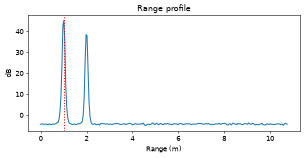

strongest target at 1.01 m (bin 24)


In [4]:
range_fft = np.fft.fft(frame * np.hanning(num_samples), axis=-1)    # [chirp, rx, range]
range_profile_db = 20 * np.log10(np.abs(range_fft).mean(axis=(0, 1)))
target_range_bin = int(np.argmax(range_profile_db[1:])) + 1          # skip the DC bin
ranges_m = np.arange(num_samples) * range_step

plt.plot(ranges_m, range_profile_db)
plt.axvline(ranges_m[target_range_bin], color="red", linestyle=":")
plt.gca().set(xlabel="Range (m)", ylabel="dB", title="Range profile")
plt.show()
print(f"strongest target at {ranges_m[target_range_bin]:.2f} m (bin {target_range_bin})")

## 2. Doppler FFT: the range-Doppler map

A second FFT, over the chirps, measures the phase change from chirp to chirp: velocity (see
[Velocity range and resolution](configuration.md#velocity-range-and-resolution)). With DDM, each TX's copy of the target sits W = chirps / N bins after the previous
one, and one sub-band stays empty.

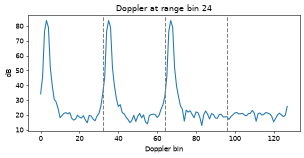

strongest Doppler bins: [3, 35, 67] (W = 32)


In [5]:
spectrum = np.fft.fft(range_fft * np.hanning(num_chirps)[:, None, None], axis=0)  # [Doppler, rx, range]
power = (np.abs(spectrum) ** 2).sum(axis=1).T                                      # [range, Doppler]
W = num_chirps // bands

plt.plot(10 * np.log10(power[target_range_bin]))
for b in range(1, bands):
    plt.axvline(b * W, color="gray", linestyle="--")
plt.gca().set(xlabel="Doppler bin", ylabel="dB", title=f"Doppler at range bin {target_range_bin}")
plt.show()
print("strongest Doppler bins:", sorted(np.argsort(power[target_range_bin])[-num_tx:].tolist()), f"(W = {W})")

## 3. Fold and find the velocity

The firmware averages the dB levels of the N sub-bands ("folds" the map) and detects targets on
the folded map, W bins wide. At the detected bin *b0*, the TX copies sit in N_TX consecutive
sub-bands (wrapping around), so TX0 is the first sub-band of the strongest run of N_TX
consecutive sub-bands. With one empty sub-band (N = N_TX + 1) that is simply the sub-band after
the weakest one, but with more empty sub-bands the weakest one need not be just before TX0.
TX0's bin is then the target's true Doppler bin. The velocity comes out in whole Doppler bins
(0.32 m/s here), so a 1 m/s target reads as the nearest bin, about 0.97 m/s.

In [6]:
folded_db = (10 * np.log10(power)).reshape(num_samples, bands, W).mean(axis=1)  # [range, W]
b0 = int(np.argmax(folded_db[target_range_bin]))
band_power = power[target_range_bin, b0::W]          # one value per sub-band
run_power = [sum(band_power[(start + m) % bands] for m in range(num_tx)) for start in range(bands)]
tx0 = int(np.argmax(run_power))                      # first sub-band of the strongest TX run
doppler_bin = b0 + W * tx0
signed_bin = doppler_bin - num_chirps if doppler_bin >= num_chirps // 2 else doppler_bin

print("sub-band levels (dB):", np.round(10 * np.log10(band_power / band_power.max()), 1))
print(f"TX0 in sub-band {tx0}, Doppler bin {signed_bin}")
print(f"velocity {signed_bin * velocity_step:+.2f} m/s (simulated: {TRUE_VELOCITY_MPS:+.2f})")

sub-band levels (dB): [ -0.   -0.    0.  -63.6]
TX0 in sub-band 0, Doppler bin 3
velocity +0.97 m/s (simulated: +1.00)


## 4. Virtual array

TX *m*'s copy of the target is at bin b0 + W · (TX0 sub-band + m). Reading it on all RX gives
the 3 × 4 virtual array: one complex value per TX-RX pair.

In [7]:
virtual = np.array([spectrum[(b0 + W * (tx0 + m)) % num_chirps, :, target_range_bin]
                    for m in range(num_tx)])        # [tx, rx]
print("phase (deg) relative to TX0/RX0:")
print(np.round(np.degrees(np.angle(virtual / virtual[0, 0]))))

phase (deg) relative to TX0/RX0:
[[  -0.  -62. -123.  175.]
 [  -0.  -62. -123.  175.]
 [  -0.  -62. -123.  175.]]


## 5. Angle

On the AWR1843AOP the RX antennas are half a wavelength apart in azimuth, so the phase step
from one RX to the next is π · sin(azimuth); an FFT across the RX (zero-padded) finds it. On this
board the RX axis of the virtual array is azimuth and the TX axis is elevation: for a target at
elevation 0 the TX phases are equal, as the printout above shows.

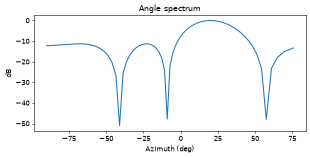

azimuth +20.1 deg (simulated: +20.0)


In [8]:
by_position = virtual[:, np.argsort(RX_AZIMUTH)]     # RX sorted by azimuth position 0, 1, 2, 3
K = 64
angle_spectrum = np.abs(np.fft.fftshift(np.fft.fft(by_position, K, axis=1), axes=1)) ** 2
angle_spectrum = angle_spectrum.sum(axis=0)          # add the TX rows
sin_azimuth = 2 * (np.arange(K) - K // 2) / K
azimuth_deg = np.degrees(np.arcsin(np.clip(sin_azimuth, -1, 1)))

plt.plot(azimuth_deg, 10 * np.log10(angle_spectrum / angle_spectrum.max()))
plt.gca().set(xlabel="Azimuth (deg)", ylabel="dB", title="Angle spectrum")
plt.show()
print(f"azimuth {azimuth_deg[np.argmax(angle_spectrum)]:+.1f} deg (simulated: {TRUE_AZIMUTH_DEG:+.1f})")

## 6. Static removal

A static reflector has Doppler bin 0, so its TX copies land at bins 0, W and 2W. Subtracting each
chirp slot's mean over the loops (`remove_static`) removes exactly those bins, every TX copy
included. The firmware's own clutter removal does not work with DDM (see
[Unsupported options](configuration.md#unsupported-options)).

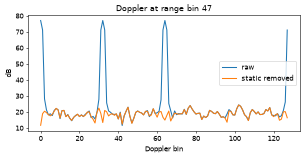

bins 0, W, 2W before / after (dB): [77. 77. 77.] [12. 13. 15.]


In [9]:
from ddm.dsp import doppler_spectrum, remove_static

static_bin = int(round(2.0 / range_step)) if CAPTURE is None else target_range_bin
before = (np.abs(doppler_spectrum(frame)) ** 2).sum(axis=1)[:, static_bin]
after = (np.abs(doppler_spectrum(remove_static(frame, bands))) ** 2).sum(axis=1)[:, static_bin]

plt.plot(10 * np.log10(before), label="raw")
plt.plot(10 * np.log10(after + 1e-12), label="static removed")
plt.gca().set(xlabel="Doppler bin", ylabel="dB", title=f"Doppler at range bin {static_bin}")
plt.legend()
plt.show()
print("bins 0, W, 2W before / after (dB):", np.round(10 * np.log10(before[[0, W, 2 * W]])),
      np.round(10 * np.log10(after[[0, W, 2 * W]] + 1e-12)))

## 7. The same in one call

`ddm.dsp` has these steps as functions; `ddm decode` and `ddm live` use them. They reproduce the
results above, so you can move from this notebook to the library.

In [10]:
from ddm.dsp import ddm_virtual_array, find_targets, fold, range_doppler_power, signed_doppler_bin, tx0_band

power_lib = range_doppler_power(frames[:1])                       # [range, Doppler]
(r, b), *_ = find_targets(fold(power_lib, bands))
tx0_lib = int(tx0_band(power_lib[r, b::W], num_tx))
virtual_lib, _ = ddm_virtual_array(doppler_spectrum(frame), bands, num_tx)  # [folded bin, range, tx, rx]

velocity_lib = signed_doppler_bin(b, tx0_lib, W, num_chirps) * velocity_step
print(f"range {r * range_step:.2f} m, velocity {velocity_lib:+.2f} m/s")
print("same as the steps above:", (r, b, tx0_lib) == (target_range_bin, b0, tx0),
      np.allclose(virtual_lib[b, r], virtual))

range 1.01 m, velocity +0.97 m/s
same as the steps above: True True
